# Lab | Transformers

---

**Note: for GPU acceleration, run this notebook in [Google Colab](https://colab.research.google.com/).**



### Section structure

1. The open-source ecosystem: increasing accessibility to machine learning (ML) software and hardware
2. Some simple code demonstrations
3. Q&A

## 1. Ease-of-use: Using Transformers in 3 lines of code


**Overview of different tasks that can be automated with ML**
* Key ingredients: (1) a model trained on a specific task; (2) input data (e.g. texts or images); (3) output produced by the model.
* Transformers are currently the most popular type of deep learning algorithm. Most tasks below are solved with Transformers. There might be other types of algorithms coming up in the medium term.



**Install the Transformers library & dependencies**

In [1]:
import os
os.environ["USE_TF"] = "0"        # tell transformers not to load TensorFlow
os.environ["USE_TORCH"] = "1"     # use PyTorch only

In [1]:
!pip install "transformers<5"

In [2]:
import transformers
print(transformers.__version__)   # should print 4.57.6

4.57.6


In [3]:
!pip install transformers  # The Transformers library from Hugging Face
!pip install sentencepiece
!pip install wikipedia
!pip install accelerate
!pip install tf-keras
!pip install torch

# NOTE: you might need to restart you jupyter kernel after installing the libraries

**The Hugging Face Pipeline**
* Makes automation of many NLP tasks possible in 3 lines of code
* Detailed documentation is available [here](https://huggingface.co/transformers/main_classes/pipelines.html)

In [2]:
from transformers import pipeline
import pandas as pd
import numpy as np
from pprint import pprint

Note : You might need more libraries or updates to run the cells below, if that is the case, follow the error messages and pip install accordingly. Chat gpt can help you if given the error messages.

### 2.1 Many models tailored to specific tasks


#### 2.1.1 Text classification

Let's select a popular text classification model in the [HF model hub](https://huggingface.co/models?pipeline_tag=text-classification&sort=downloads).

Here we chose "cardiffnlp/twitter-roberta-base-irony".

We will classify text into ironic or non ironic.

In [3]:
pipeline_classification = pipeline("text-classification", model="cardiffnlp/twitter-roberta-base-irony")  # cardiffnlp/twitter-roberta-base-irony, SamLowe/roberta-base-go_emotions

Device set to use mps:0


Now that we have the model we can pass it a string and have it give us a classification.

Feel free to experiment with different sentences by changing the contents of the variable text

In [4]:
text = "Well that workshop was totally worth my time..."  # "Well that workshop was totally worth my time..."  "This smells weird, I'm not sure if I should eat this ... Yikes, it tasted like old socks!"
output = pipeline_classification(text, top_k=10)
print(output)

[{'label': 'irony', 'score': 0.9424386620521545}, {'label': 'non_irony', 'score': 0.057561296969652176}]


Let's make the output a little cleaner

In [5]:
# make output a bit cleaner
df_output = pd.DataFrame(output)
print(df_output)

       label     score
0      irony  0.942439
1  non_irony  0.057561


As you can see, in a few lines of code and by leveraging an existing model we can classify text as ironic or non ironic. Now you have one more tool in your machine learning toolbox.

Remember that : 'when you only have a hammer everything is a nail'. But if we want to build a house (perform machine learning the right way), we need to use the right tool for the right job.

#### 2.1.2 Machine Translation

* Open source machine translation (MT) models enable you to translate between many different languages without Google Translate.
* [University of Helsinki](https://huggingface.co/Helsinki-NLP) uploaded models for more than 1000 language pairs to the Hugging Face hub
* [Facebook AI](https://huggingface.co/models?search=facebook+m2m) open-sourced several multi-lingual models
* The [EasyNMT library](https://github.com/UKPLab/EasyNMT), provides an easy wrapper for all these models
* Most machine translation models translate between two languages in one direction (e.g. German to English, but not English to German), some can translate in multiple directions.


In [6]:
# translation pipeline docs: https://huggingface.co/transformers/main_classes/pipelines.html#transformers.TranslationPipeline
pipeline_translate = pipeline("translation", model="facebook/m2m100_418M")

pytorch_model.bin:   0%|          | 0.00/1.94G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.94G [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use mps:0


M2M100 is a multilingual encoder-decoder (seq-to-seq) model trained for Many-to-Many multilingual translation.

The model that can directly translate between the 9,900 directions of 100 languages.

Here we specify to translate from German 'de' to English 'en'

In [7]:
text = "Ich bin ein Fisch"
pipeline_translate(text, src_lang="de", tgt_lang="en")

[{'translation_text': 'I am a fish'}]

Let's do the same but with and entire wikipedia page in german.

In [9]:
import wikipedia

# Wikipedia asks clients to identify themselves; the default python-requests identity is often blocked
wikipedia.wikipedia.USER_AGENT = "IronhackLab/1.0 (student learning project; rizki@example.com)"

In [10]:
# download any text from wikipedia, via  https://pypi.org/project/wikipedia/
import wikipedia
wikipedia.set_lang("de")

text = wikipedia.summary("Donald Trump").replace('\n', ' ')[:318]
print(f"Original text:\n{text}\n")

# translate the text from wikipedia
text_translated = pipeline_translate(text, src_lang="de", tgt_lang="en")
print(f"Translated text:\n{text_translated[0]['translation_text']}")


Original text:
Donald John Trump [ˈdɑn.əld dʒɑn tɹɐmp] (* 14. Juni 1946 in Queens, New York City) ist ein US-amerikanischer Politiker der Republikanischen Partei. Er war von 2017 bis 2021 der 45. und ist seit dem 20. Januar 2025 der 47. Präsident der Vereinigten Staaten. Außerdem ist er Unternehmer und ehemaliger Showmaster. Er gil

Translated text:
Donald John Trump [ˈdɑn.əld dʒɑn tɔmp] (* 14 June 1946 in Queens, New York City) is an American politician of the Republican Party. he was from 2017 to 2021 the 45th and is from 20 January 2025 the 47th President of the United States.


#### 2.1.3 Text Summarization

In [11]:
# docs for summarisation pipeline: https://huggingface.co/transformers/main_classes/pipelines.html#summarizationpipeline
pipeline_summarize = pipeline("summarization", model="sshleifer/distilbart-cnn-12-6")  # sshleifer/distilbart-cnn-12-6 , google/pegasus-cnn_dailymail

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use mps:0


In [12]:
# download any long text from wikipedia, via  https://pypi.org/project/wikipedia/
import wikipedia
wikipedia.set_lang("en")

text_long = wikipedia.summary("Donald Trump").replace('\n', ' ')
print(f"Original text:\n{text_long}\n")

# translate the text from wikipedia
text_summarized = pipeline_summarize(text_long, min_length=5, max_length=30)
print(f"Summarized text:\n{text_summarized[0]['summary_text']}")

Original text:
Donald John Trump (born June 14, 1946) is an American politician, media personality, and businessman who is the 47th president of the United States. A member of the Republican Party, he served as the 45th president from 2017 to 2021. Born into a wealthy New York City family, Trump graduated from the University of Pennsylvania in 1968 with a bachelor's degree in economics. He became the president of his family's real estate business in 1971, renamed it the Trump Organization, and began acquiring and building skyscrapers, hotels, casinos, and golf courses. He launched side ventures, many licensing the Trump name, and filed for six business bankruptcies in the 1990s and 2000s. From 2004 to 2015, he hosted the reality television show The Apprentice, bolstering his reputation as a wealthy tycoon. Presenting himself as a political outsider, Trump won the 2016 presidential election against Democratic Party nominee Hillary Clinton. During his first presidency, Trump imposed a tr

#### 2.1.4 Named Entity Recognition

NER is a task that involves identifying and classifying specific entities in text into predefined categories, such as names of people, organizations, locations, dates, and more. 

For example, in the sentence "Apple Inc. was founded by Steve Jobs in California," NER would recognize "Apple Inc." as an organization, "Steve Jobs" as a person, and "California" as a location.

In [13]:
pipeline_ner = pipeline("token-classification", model="dslim/bert-base-NER-uncased", aggregation_strategy="simple")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Some weights of the model checkpoint at dslim/bert-base-NER-uncased were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use mps:0


In [14]:
import wikipedia
wikipedia.set_lang("en")

text_long = wikipedia.summary("Donald Trump").replace('\n', ' ')

output = pipeline_ner(text_long)

pd.DataFrame(output)

,entity_group,score,word,start,end
0,PER,0.985104,donald john trump,0,17
1,MISC,0.984194,american,45,53
2,LOC,0.986981,united states,134,147
3,MISC,0.789240,republican,165,175
4,ORG,0.722175,party,176,181
5,LOC,0.891513,new york city,254,267
6,PER,0.977508,trump,276,281
7,ORG,0.668196,university of pennsylvania,301,327
8,ORG,0.849597,trump organization,460,478
9,PER,0.920151,trump,607,612


### 2.2. Universal models

The models mentioned above are designed to excel at a single specific task on a particular dataset. The key advantage of these models is their high performance and accuracy on that specific task and dataset. 

However, in real-world applications, the problems you'll face often require solving slightly different tasks, possibly with varied category definitions or applied to different types of texts.

Universal models can help address this challenge. Although they also focus on one task, the task is general or universal enough that many other tasks can be reformulated into it. Two examples of universal tasks are:

- Natural Language Inference (NLI): A task that can effectively solve a wide range of classification tasks by determining whether a given premise supports, contradicts, or is neutral with respect to a hypothesis.

- Token Generation: An even more universal task that can be applied to solve virtually any text-related task, including translation, summarization, and text completion.

These universal tasks enable the models to be versatile and adaptable to various problems beyond the specific ones they were initially trained on.

#### Zero-shot classification


Zero-shot classification is a technique where a model can categorize data into classes it has never seen before. 

Instead of relying on labeled examples for each class, the model understands the relationship between the input and the class descriptions, allowing it to make accurate predictions without needing specific training on those classes.

In [15]:
pipeline_zeroshot_classification = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")

config.json: 0.00B [00:00, ?B/s]

/opt/anaconda3/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.3M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Device set to use mps:0


Here we will give the model a list of classes ('payment issues', 'travel advice', 'bug report') for it to classify our string.

In [16]:
text = "Customer: I have not received my reimbursement yet. What the hell is going on?"
classes = ['payment issues', 'travel advice', 'bug report']  # "account opening", "customer complaint"

#text = "I do not think the government is trustworthy anymore. We need to mobilize and resist!"
#classes = ["civil disobedience", "praise of the government", "travel advice"]  # "collective action"

output = pipeline_zeroshot_classification(text, classes, multi_label=True)

pd.DataFrame(data=[output["labels"], output["scores"]], index=["class", "probability"]).T


,class,probability
0,payment issues,0.991161
1,bug report,0.076132
2,travel advice,0.01896


## Exercise

Now it is your turn to go to the hugging face library https://huggingface.co/models?pipeline_tag=text-classification&sort=downloads

(you can select on the left menu of the website the type of NLP tasks you want models to perform)

- Find an NLP model that we have not used previously.

- Get some data from wikipedia or elsewhere.

- Perform inference with the model and print the result!

- Comment your code along the way, describe what your model does and what your end goal is from input to output.

Have fun!

In [18]:
# Your code here :

# Exercise: extractive question answering with a model we have not used yet.
# Goal: question + Wikipedia text (context) -> the span of the text that answers the question, plus a confidence score.
qa_pipeline = pipeline("question-answering", model="deepset/roberta-base-squad2")

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/496M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

Device set to use mps:0


In [19]:
import wikipedia
wikipedia.set_lang("en")

# Take the first part of the Wikipedia article on coffee as our "menu" for the model to read
coffee_page = wikipedia.page("Coffee", auto_suggest=False)
context = coffee_page.content[:4000].replace("\n", " ")

print(f"Characters in context: {len(context)}")
print(context[:500] + " ...")

Characters in context: 4000
Coffee is a beverage brewed from roasted, ground coffee beans. Dark-colored and bitter, coffee has a stimulating effect on humans due to its caffeine content; however decaffeinated coffee is also commercially available. There are also various coffee substitutes. Coffee production begins when the seeds from coffee cherries, the Coffea plant's fruits, are separated to produce unroasted green coffee beans. The "beans" are roasted and then ground into fine particles. Coffee is brewed from the ground ...


In [20]:
question = "Where do coffee beans come from?"
result = qa_pipeline(question=question, context=context)

print(result)
# score  = how confident the model is (0 to 1)
# start/end = character positions of the answer inside the context
# answer = the text found between start and end

{'score': 0.512808084487915, 'start': 1201, 'end': 1206, 'answer': 'Yemen'}


In [21]:
questions = [
    "Where do coffee beans come from?",
    "What is the stimulant in coffee?",
    "Which plant is coffee made from?",
    "How is coffee usually prepared?",
]

rows = []
for q in questions:
    r = qa_pipeline(question=q, context=context)
    rows.append({
        "question": q,
        "answer": r["answer"],
        "score": round(r["score"], 3),
        "start": r["start"],
        "end": r["end"],
    })

df_qa = pd.DataFrame(rows)
df_qa

,question,answer,score,start,end
0,Where do coffee beans come from?,Yemen,0.513,1201,1206
1,What is the stimulant in coffee?,caffeine,0.704,141,149
2,Which plant is coffee made from?,"roasted, ground coffee beans",0.187,33,61
3,How is coffee usually prepared?,served hot,0.178,598,608


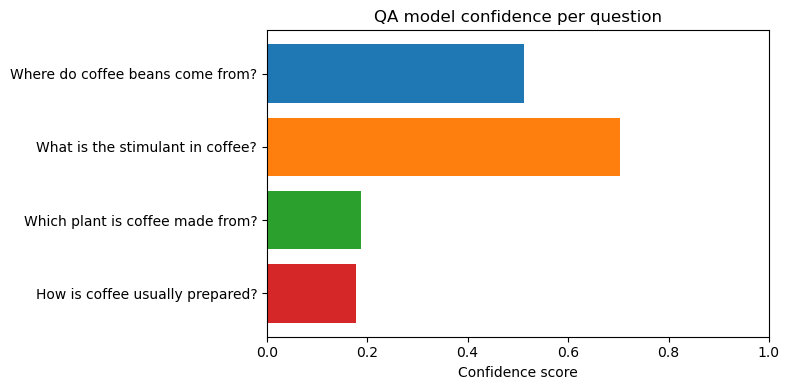

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(df_qa["question"], df_qa["score"], color=[f"C{i}" for i in range(len(df_qa))])
ax.set_xlabel("Confidence score")
ax.set_xlim(0, 1)
ax.invert_yaxis()  # first question on top
ax.set_title("QA model confidence per question")
plt.tight_layout()
plt.show()

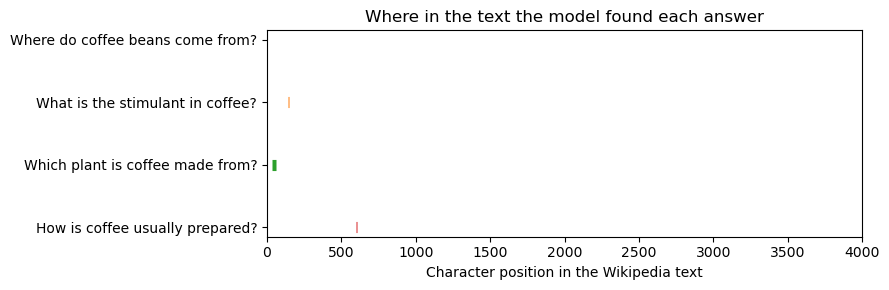

In [23]:
fig, ax = plt.subplots(figsize=(9, 3))

# Each answer is drawn as a coloured block on a line that represents the whole context
for i, row in df_qa.iterrows():
    ax.hlines(y=i, xmin=row["start"], xmax=row["end"], color=f"C{i}", linewidth=8)

ax.set_xlim(0, len(context))
ax.set_yticks(range(len(df_qa)))
ax.set_yticklabels(df_qa["question"])
ax.invert_yaxis()
ax.set_xlabel("Character position in the Wikipedia text")
ax.set_title("Where in the text the model found each answer")
plt.tight_layout()
plt.show()

**What I did:** I used `deepset/roberta-base-squad2`, a question-answering model, which we had not used in the lab before.
It reads a question and a context (the first 4000 characters of the Wikipedia article on coffee) and returns the span of
the text that answers the question, plus a confidence score.

**Input -> output:** (question, Wikipedia text) -> (answer text, score, start/end position).

**Takeaway:** the model does not invent answers. It points to a piece of the text, so a low score usually means the
answer is not in the context I gave it.
